# Phân tích hành vi model

Hai model cùng đạt accuracy cao trên tập test, nhưng khi đổi sang ảnh từ camera khác thì một model sai gần hết. Lý do có thể là model đã học một dấu hiệu tình cờ đi cùng nhãn, ví dụ một vệt ở góc ảnh, thay vì học chính vật cần nhận ra. Bài này học cách kiểm model dựa vào thông tin gì: thay đổi một yếu tố của ảnh rồi đo kết quả đổi ra sao, sau đó dùng các phương pháp tô vùng ảnh ảnh hưởng tới dự đoán.

> **Mục tiêu**
>
> - So hai model trên từng mẫu và từng nhóm dữ liệu.
> - Thiết kế thí nghiệm kiểm model có dùng dấu hiệu tình cờ không.
> - Dùng occlusion, saliency, Grad-CAM và biết giới hạn của chúng.

## Điểm tổng che khuất điều gì?

Accuracy là một trung bình. Một model có thể đúng ở ảnh sáng và sai ở ảnh tối, đúng người chụp cũ và sai người chụp mới. Trước khi nhìn heatmap, ta giữ từng prediction cùng ID, nhãn, score và các thuộc tính hợp lệ như camera hoặc kích thước vật thể.

Chia lỗi thành nhóm giúp đặt câu hỏi cụ thể: sai vì nhầm lớp, thiếu vùng nhỏ, background khác hay preprocessing? Trong mỗi nhóm, đọc nhiều chỉ số chứ không chỉ một: hai nhóm có cùng recall vẫn có thể có precision khác hẳn khi tỉ lệ lớp dương của chúng khác nhau. Ghi số mẫu cạnh mỗi chỉ số; một nhóm vài ảnh chỉ cho một gợi ý.

Nếu so A và B, cần cùng mẫu và cùng metric. Bảng chéo đúng/sai theo ID có bốn ô: cả hai đúng, chỉ A đúng, chỉ B đúng, cả hai sai. Hai ô giữa mới chứa thông tin phân biệt hai model, nên hai score tổng bằng nhau vẫn có thể che việc A đúng ở mẫu B sai và ngược lại.

Ô cả hai sai là nơi nên xem ảnh trước: đổi model chưa cứu được chúng, nhiều khi vì nhãn sai hoặc ảnh thiếu thông tin.

**Hỏi nhanh.** Trên cùng 100 ảnh validation, A và B đều đúng 90 ảnh. Có 6 ảnh A đúng còn B sai. Có bao nhiêu ảnh cả hai cùng sai?

- A. 0
- B. 4
- C. 6
- D. 10

<details><summary>Đáp án</summary>

B. 4

Gọi $k$ là số ảnh cả hai đều đúng. A đúng $k + 6 = 90$ ảnh, nên $k = 84$. Số ảnh B đúng mà A sai là $90 - 84 = 6$. Vậy số ảnh cả hai cùng sai là $100 - 84 - 6 - 6 = 4$. 10 là giả định hai model sai đúng trên cùng những ảnh. 6 là nhầm ô “chỉ A đúng” với ô cả hai sai. 0 là giả định lỗi của hai model không giao nhau, điều chỉ xảy ra khi mỗi phía có 10 ảnh lệch.

</details>



Chỉ xem ảnh sai được chọn theo cảm giác dễ bỏ sót một nhóm. Lấy mẫu đúng/sai theo tiêu chí đã ghi, kiểm cả những ảnh model tự tin nhưng sai. Dữ liệu chụp theo nhóm còn có phụ thuộc; 100 frame gần nhau không tương đương 100 buổi độc lập.

**Hỏi nhanh.** Model sai 300 ảnh validation, nhưng ta chỉ đủ thời gian xem kỹ 30 ảnh. Chọn 30 ảnh nào thì bức tranh về lỗi đáng tin nhất?

- A. 30 ảnh sai đầu tiên theo tên tệp, vì thứ tự tên tệp coi như ngẫu nhiên
- B. 30 ảnh có heatmap rõ nhất, vì dễ giải thích cho cả đội
- C. 30 ảnh có score sát ngưỡng 0.5, vì đó là những ảnh khó nhất
- D. Lấy ngẫu nhiên trong từng nhóm, thêm vài ảnh sai mà score rất cao

<details><summary>Đáp án</summary>

D. Lấy ngẫu nhiên trong từng nhóm, thêm vài ảnh sai mà score rất cao

Tên tệp thường gom theo nguồn, theo lớp hoặc theo buổi chụp, nên 30 ảnh đầu có thể cùng một buổi. Chọn heatmap rõ là chọn theo cảm giác, mà heatmap chưa phải bằng chứng. Ảnh sát ngưỡng chỉ cho thấy lỗi ở biên quyết định. Lấy ngẫu nhiên theo nhóm thì ước lượng được tỉ lệ của từng loại lỗi. Còn ảnh sai mà model rất tự tin thường chỉ ra nhãn sai hoặc một đường tắt.

</details>

## Một đường tắt được tạo để ta kiểm rõ

Ta quay lại ảnh nét: nhãn 0 là đứng, 1 là ngang. Trong tập nguồn, ảnh ngang tình cờ có ô góc sáng, ảnh đứng có ô góc tối. Model có thể dùng góc thay vì nét. Trên validation cùng quy luật, cả hai cách đều đúng; thay đổi dấu góc sẽ tách chúng.



Ta tự thiết kế dữ liệu để biết quy tắc nhãn. Trong ảnh thật, xóa nền có thể vô tình xóa bóng hoặc viền vật thể; việc giữ nhãn phải được kiểm, không tự tuyên bố.

In [ ]:
import numpy as np
from sklearn.linear_model import LogisticRegression

vertical = np.zeros((8, 8))
vertical[2:6, 3:5] = 1
horizontal = np.zeros((8, 8))
horizontal[3:5, 2:6] = 1
orientation_filter = (horizontal - vertical) / 4

def make_images(count, seed, reverse_corner=False):
    rng = np.random.default_rng(seed)
    labels = np.arange(count) % 2
    images = np.zeros((count, 8, 8))
    for index, label in enumerate(labels):
        images[index] = vertical if label == 0 else horizontal
        marker = 1 - label if reverse_corner else label
        images[index, :2, :2] = marker
    images += rng.normal(0, 0.02, images.shape)
    return np.clip(images, 0, 1), labels

def features(images):
    corner = images[:, :2, :2].mean(axis=(1, 2))
    shape = (images * orientation_filter).sum(axis=(1, 2))
    return corner[:, None], shape[:, None]

train_images, train_labels = make_images(80, 1)
normal_images, labels = make_images(40, 2)
changed_images, changed_labels = make_images(40, 2, reverse_corner=True)
train_corner, train_shape = features(train_images)
model_a = LogisticRegression().fit(train_corner, train_labels)
model_b = LogisticRegression().fit(train_shape, train_labels)
print("same labels after intervention:", np.array_equal(labels, changed_labels))
print("shape features preserved:",
      np.allclose(features(normal_images)[1], features(changed_images)[1]))

same labels after intervention: True
shape features preserved: True


Model A chỉ thấy độ sáng trung bình của ô góc, model B chỉ thấy shape score (điểm hướng nét); cả hai là logistic regression một đặc trưng. Một CNN thật tự chọn đặc trưng nên ta không biết trước nó dùng gì; ở đây ta biết trước, nhờ vậy kiểm được phép đánh giá có phát hiện đúng điều đã cài hay không.

Shape filter nằm ở giữa ảnh, không đọc góc; hai dòng `True` xác nhận phép đổi góc giữ nhãn và giữ nguyên tín hiệu hướng.

### Ví dụ tính tay

Shape score bằng tổng ảnh nhân $(H-V)/4$. Template ngang và template đứng mỗi cái 8 ô, chung nhau 4 ô ở giữa. Filter vì thế có bốn ô $+1/4$ (chỉ thuộc nét ngang), bốn ô $-1/4$ (chỉ thuộc nét đứng), còn lại bằng 0. Với nét ngang sạch, bốn ô $+1/4$ đều sáng và bốn ô $-1/4$ đều tối, nên score bằng $+1$; nét đứng cho $-1$. Dấu góc nằm ngoài filter nên không góp vào score.



**Hỏi nhanh.** Trong code, nét ngang chiếm `[3:5, 2:6]`. Dịch nó xuống một hàng thành `[4:6, 2:6]`, ảnh sạch, dấu góc giữ nguyên. Shape score bằng bao nhiêu?

- A. $+1$
- B. $+0.5$
- C. $0$
- D. $-1$

<details><summary>Đáp án</summary>

C. $0$

Hàng 4 vẫn nằm trong template ngang. Hai ô ngoài, ở cột 2 và 5, cho mỗi ô $+1/4$. Hai ô giữa thuộc phần chung nên bằng 0. Hàng 4 cộng $+0.5$. Hàng 5 nằm ngoài template ngang, nhưng cột 3 và 4 của nó thuộc phần chỉ có ở template đứng, nên cộng $-0.5$. Tổng bằng 0: filter cố định vị trí không còn phân biệt được hướng nét. $+1$ là nghĩ filter tự đi theo nét như convolution. $+0.5$ là quên hàng 5. $-1$ là score của nét đứng.

</details>

## So hai model bằng cùng một can thiệp

Ta đo accuracy ở ảnh nguồn bình thường và ảnh đổi góc. Cùng seed nhiễu, cùng hướng nét, chỉ đổi nội dung dấu góc, nên khác biệt có một nguyên nhân được kiểm soát trong bộ dữ liệu này.

In [ ]:
def predict_both(images):
    corner, shape = features(images)
    return model_a.predict(corner), model_b.predict(shape)

for name, images in [("normal", normal_images), ("changed corner", changed_images)]:
    pred_a, pred_b = predict_both(images)
    print(name, "A/B accuracy:",
          round(np.mean(pred_a == labels), 3),
          round(np.mean(pred_b == labels), 3))

pred_a, pred_b = predict_both(changed_images)
print("A correct, B wrong:", int(np.sum((pred_a == labels) & (pred_b != labels))))
print("B correct, A wrong:", int(np.sum((pred_b == labels) & (pred_a != labels))))

normal A/B accuracy: 1.0 1.0
changed corner A/B accuracy: 0.0 1.0
A correct, B wrong: 0
B correct, A wrong: 40


Trên normal, cả hai đúng; trên changed corner, A thất bại còn B giữ kết quả. Hai dòng đếm theo từng ảnh cho thấy mọi khác biệt đi một chiều: 40 ảnh B đúng mà A sai, không ảnh nào ngược lại. Ta có bằng chứng A phụ thuộc dấu góc trong dữ liệu đã viết.

Chưa suy ra được B bền với mọi camera: B dùng filter ở vị trí cố định, nên nét dịch chỗ hoặc đổi kích thước có thể làm shape score mất ý nghĩa. Mục “Tìm lỗi có hệ thống” đo điều này.

Trên model thật, một can thiệp hợp lệ có thể là thay background, che watermark hoặc đổi sáng trong mức hợp lý. Ta bắt đầu bằng giả thuyết, giữ nhãn, chạy cùng mẫu trước/sau và ghi tỉ lệ đổi nhãn cùng mức đổi score. Nếu can thiệp làm ảnh xa phân phối thật, kết quả nói về điều kiện ấy, chưa trực tiếp nói về sử dụng thường ngày.

**Hỏi nhanh.** Trên tập changed corner, A có accuracy 0.0 chứ không phải khoảng 0.5. Con số này nói lên điều gì?

- A. Quyết định của A đi theo dấu góc trên mọi ảnh
- B. A đoán gần như ngẫu nhiên khi gặp ảnh lạ
- C. Nhãn của tập changed corner đã bị đảo nhầm
- D. A học được hướng nét, nhưng theo chiều ngược lại

<details><summary>Đáp án</summary>

A. Quyết định của A đi theo dấu góc trên mọi ảnh

Đổi góc thì từng quyết định của A đều bị đảo. Model vẫn “chắc chắn”, chỉ là chắc chắn theo góc. Đảo mọi dự đoán của A thì sẽ được 1.0. Đoán ngẫu nhiên thì cho khoảng 0.5. Nhãn không bị đảo, dòng `same labels after intervention: True` đã kiểm điều đó. A hoàn toàn không nhận shape feature, nên không thể học hướng nét theo chiều nào.

</details>

**Hỏi nhanh.** Nếu sinh `changed_images` bằng seed nhiễu 3 thay vì seed 2 như `normal_images`, phép so trước và sau mất đi điều gì?

- A. Không mất gì, vì nhiễu chỉ có độ lệch chuẩn 0.02
- B. Nhãn của hai tập không còn khớp nhau theo từng ID
- C. Model B không còn dự đoán được trên ảnh mới
- D. Mất phép so cặp, vì mỗi cặp khác nhau cả nhiễu lẫn dấu góc

<details><summary>Đáp án</summary>

D. Mất phép so cặp, vì mỗi cặp khác nhau cả nhiễu lẫn dấu góc

Cùng seed thì mỗi ảnh đổi góc là bản sao của đúng một ảnh normal, chỉ khác bốn ô góc. Dự đoán nào thay đổi cũng chỉ có một nguyên nhân. Đổi seed thì mỗi cặp khác nhau thêm cả nhiễu. Ở đây nhiễu nhỏ nên accuracy vẫn là 0.0 và 1.0. Nhưng với ảnh thật, những khác biệt phụ ngoài ý muốn như crop, nén hay ánh sáng thường không nhỏ. Nhãn vẫn khớp vì chúng được sinh theo thứ tự `arange % 2`, và B chạy được trên mọi ảnh $8\times 8$.

</details>

## Occlusion: che vùng rồi xem score đổi

Occlusion thay một vùng ảnh bằng giá trị nền hoặc mẫu khác, chạy lại model và xem score của **cùng lớp** thay đổi. Nó gần với thử bỏ một đặc trưng: nếu score giảm nhiều, vùng ấy có ảnh hưởng theo phép thay đã dùng.

Ta chọn một ảnh ngang, lớp 1. Che góc và che vùng nét riêng. Code đọc xác suất của lớp 1 cho cả hai model, cả trước lẫn sau khi che.

In [ ]:
example = normal_images[1].copy()
without_corner = example.copy()
without_corner[:2, :2] = 0
without_shape = example.copy()
without_shape[2:6, 2:6] = 0
batch = np.stack([example, without_corner, without_shape])
corner, shape = features(batch)
score_a = model_a.predict_proba(corner)[:, 1]
score_b = model_b.predict_proba(shape)[:, 1]
print("rows: original, cover corner, cover shape")
print("A probability of class 1:", score_a.round(4).tolist())
print("B probability of class 1:", score_b.round(4).tolist())

rows: original, cover corner, cover shape
A probability of class 1: [0.891, 0.1057, 0.891]
B probability of class 1: [0.9589, 0.9589, 0.4995]




Nhìn dòng A khi che góc ($0.891 \to 0.1057$) và dòng B khi che nét ($0.9589 \to 0.4995$). Mỗi model chỉ phản ứng với vùng nó đọc; che vùng còn lại không đổi score đến chữ số thứ tư. Che nét đồng thời bỏ đối tượng quyết định nhãn, nên ảnh ấy không phải một mẫu validation giữ nguyên nhãn; nó chỉ phục vụ đo độ phụ thuộc của score.

**Hỏi nhanh.** Che góc làm A đổi argmax từ lớp 1 sang lớp 0. Vì sao ta vẫn đọc xác suất của lớp 1, cả trước lẫn sau khi che?

- A. Để model không thể đổi nhãn dự đoán sau khi che
- B. Để so cùng một đại lượng trước và sau khi che
- C. Vì xác suất hai lớp luôn bằng nhau sau khi che
- D. Vì lớp argmax mới luôn có score thấp hơn lớp cũ

<details><summary>Đáp án</summary>

B. Để so cùng một đại lượng trước và sau khi che

Với A, $p_1$ đi từ 0.891 xuống 0.1057. Nếu đọc xác suất của lớp đang được dự đoán, ta sẽ so $p_1 = 0.891$ với $p_0 = 1 - 0.1057 = 0.8943$, và tưởng che góc không có tác động gì. Đọc cùng một lớp không ngăn model đổi nhãn, chỉ giữ cho thước đo cố định. Hai xác suất chỉ bằng nhau khi đúng bằng 0.5. Còn lớp argmax mới, theo định nghĩa, có score cao hơn lớp kia.

</details>

Chọn màu che ảnh hưởng kết quả. Ô đen trong ảnh rất sáng có thể tự là tín hiệu lạ. Muốn kết luận vững hơn, thử nhiều baseline, nhiều kích thước cửa sổ và nhóm ảnh; kiểm score có giảm vì vùng cần thiết hay vì tạo nhiễu ngoài phân phối. Một cửa sổ đo tác động khi mọi vùng khác giữ nguyên, nên khi nghi model có hai tín hiệu thay thế nhau, che cả tổ hợp vùng.

Trên ảnh lớn, occlusion map trượt cửa sổ khắp ảnh, mỗi vị trí một lượt forward. Chi phí tăng theo số vị trí nhân số ảnh; gộp các ảnh đã che thành batch như code trên, và chỉ chạy trên một mẫu ảnh chọn theo tiêu chí.



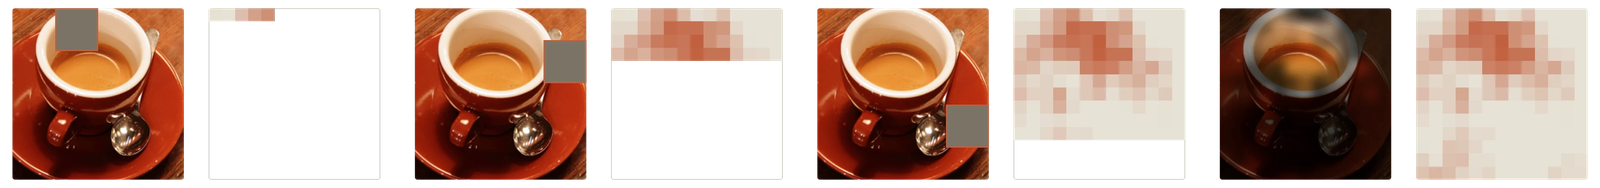

**Hỏi nhanh.** Ảnh $224\times 224$, cửa sổ che $16\times 16$, bước trượt 8 theo cả hai chiều, không padding. Không kể ảnh gốc, một ảnh cần bao nhiêu lượt forward để vẽ occlusion map?

- A. 196
- B. 729
- C. 784
- D. 50 176

<details><summary>Đáp án</summary>

B. 729

Mỗi chiều có $(224 - 16)/8 + 1 = 27$ vị trí, nên có $27^2 = 729$ lượt. 196 bằng $(224/16)^2$, ứng với cửa sổ không chồng nhau. 784 bằng $(224/8)^2$, quên rằng cửa sổ phải nằm trọn trong ảnh. 50 176 là che từng pixel. Với 1000 ảnh validation đã là 729 000 lượt forward, nên khi thi chỉ chạy trên một mẫu ảnh có chọn lọc.

</details>

## Saliency và Grad-CAM thêm góc nhìn nào?

Saliency dùng gradient của score lớp theo input để đo nhạy cảm cục bộ: thay một pixel rất nhỏ có thể đổi score thế nào. Occlusion cần một lượt forward cho mỗi vùng; saliency chỉ cần một lượt forward và một lượt backward cho cả ảnh.

Cái giá là nó chỉ nhìn thay đổi vô cùng nhỏ: gradient lớn không luôn nghĩa pixel đó là nguyên nhân ngữ nghĩa quan trọng, và gradient có thể bão hòa hoặc nhạy với noise. Qua ReLU hay max pooling, gradient bằng 0 ở các nhánh không được chọn, nên một vùng có ích vẫn có thể có saliency bằng 0.

Hai model của bài đọc pixel bằng phép tính viết lại được trong torch, nên autograd tính saliency trực tiếp. Ta lấy gradient của logit (score trước sigmoid) theo 64 pixel của ảnh ngang dùng ở mục occlusion, đo phần gradient nằm ở ô góc, rồi so với map của một ảnh đứng.

In [ ]:
import torch

shape_filter = torch.tensor(orientation_filter)
readers = {
    "A": (model_a, lambda pixels: pixels[:2, :2].mean()),
    "B": (model_b, lambda pixels: (pixels * shape_filter).sum()),
}

def saliency(name, image, use_probability=False):
    model, read_feature = readers[name]
    pixels = torch.tensor(image, requires_grad=True)
    score = (float(model.coef_[0, 0]) * read_feature(pixels)
             + float(model.intercept_[0]))
    if use_probability:
        score = torch.sigmoid(score)
    score.backward()
    return pixels.grad.abs().numpy()

corner = np.zeros((8, 8), dtype=bool)
corner[:2, :2] = True
for name in ["A", "B"]:
    horizontal_map = saliency(name, normal_images[1])
    vertical_map = saliency(name, normal_images[0])
    print(name, "corner:", round(horizontal_map[corner].sum() / horizontal_map.sum(), 3),
          "| max:", round(horizontal_map.max(), 4),
          "| same on vertical:", np.allclose(horizontal_map, vertical_map))
print("B max grad of probability:", round(saliency("B", normal_images[1], True).max(), 4))

A corner: 1.0 | max: 1.0688 | same on vertical: True
B corner: 0.0 | max: 0.8026 | same on vertical: True
B max grad of probability: 0.0316


A dồn toàn bộ gradient vào ô góc, B không có chút nào ở đó: khớp với occlusion. Số 1.0688 tính tay được: logit của A là hệ số của A nhân trung bình bốn ô góc, nên đạo hàm theo mỗi ô bằng hệ số ấy chia 4.

Cột `same on vertical` cho thấy giới hạn: với model tuyến tính theo pixel, gradient chính là trọng số, giống hệt nhau cho ảnh ngang và ảnh đứng. Saliency nói model nhạy ở đâu, chưa nói ảnh này có gì ở đó.

Dòng cuối là bão hòa: lấy gradient của xác suất thay cho logit, mọi giá trị nhân thêm $p(1-p)$ với $p=0.9589$, nên map nhỏ đi khoảng 25 lần đúng ở ảnh model rất tự tin.



**Hỏi nhanh.** Saliency của B trên ảnh ngang và trên ảnh đứng trùng nhau từng ô. Điều đó cho biết gì?

- A. Model tuyến tính có gradient không phụ thuộc ảnh
- B. Hai ảnh có nội dung giống nhau ở vùng giữa
- C. Autograd chưa bật nên map trả về giá trị mặc định
- D. B đã học đúng hướng nét trên mọi ảnh có thể gặp

<details><summary>Đáp án</summary>

A. Model tuyến tính có gradient không phụ thuộc ảnh

Logit của B có dạng $\mathbf{w}^\top\mathbf{x} + b$, nên đạo hàm theo $\mathbf{x}$ luôn là $\mathbf{w}$, dù ảnh ngang và ảnh đứng khác hẳn nhau ở vùng giữa. Nếu `pixels` không bật `requires_grad`, `backward()` sẽ báo lỗi chứ không trả về map mặc định. Map ổn định cũng không chứng minh B đúng khi nét bị dịch, vì filter vẫn cố định vị trí.

</details>

Grad-CAM dùng feature map ở một lớp convolution thay cho pixel. Với score $s_c$ và feature map $A^k$, lấy trung bình gradient theo không gian để có trọng số $\alpha_k$, rồi cộng các map:

$$\alpha_k=\frac{1}{HW}\sum_{i,j}\frac{\partial s_c}{\partial A^k_{i,j}},\qquad
M_c=\operatorname{ReLU}\left(\sum_k\alpha_kA^k\right).$$

$k$ là kênh, $i,j$ là vị trí. Kênh có $\alpha_k$ âm làm giảm score lớp $c$, và ReLU chỉ giữ những vùng đẩy score lên.

Chọn lớp nào để tính là một quyết định: lớp nông giữ chi tiết vị trí nhưng feature còn là cạnh, góc; lớp conv cuối mang ngữ nghĩa của lớp nhưng với ảnh $224\times224$ có thể chỉ còn $7\times7$ ô, mỗi ô ứng với một vùng $32\times32$ pixel. Phóng map lên kích thước ảnh làm nó mượt, không làm nó chính xác hơn.

Grad-CAM tổng quát hóa CAM gốc. CAM chỉ dùng được khi mạng kết thúc bằng global average pooling rồi một lớp linear: map của lớp $c$ khi đó là $\sum_k w_{c,k}A^k$ với $w$ là trọng số của lớp linear. Grad-CAM thay $w_{c,k}$ bằng $\alpha_k$ lấy từ gradient nên dùng được với kiến trúc bất kỳ, không phải sửa và train lại mạng.

Trên CNN thật, Grad-CAM giữ $A^k$ và gradient theo $A^k$ ở lớp đã chọn bằng hook; [bài báo Grad-CAM](https://arxiv.org/abs/1610.02391) mô tả phương pháp, và Captum có sẵn cài đặt.

**Hỏi nhanh.** Lớp được chọn có hai kênh $2\times 2$. Kênh $A^1 = \begin{bmatrix}1&0\\2&1\end{bmatrix}$ có mọi gradient bằng 0.5. Kênh $A^2 = \begin{bmatrix}0&3\\1&0\end{bmatrix}$ có gradient $\begin{bmatrix}-1&0\\0&-1\end{bmatrix}$. Map Grad-CAM $M_c$ bằng bao nhiêu?

- A. $\begin{bmatrix}0.5&1.5\\1.5&0.5\end{bmatrix}$
- B. $\begin{bmatrix}0.5&0\\1&0.5\end{bmatrix}$
- C. $\begin{bmatrix}0.5&0\\0.5&0.5\end{bmatrix}$
- D. $\begin{bmatrix}0.5&-1.5\\0.5&0.5\end{bmatrix}$

<details><summary>Đáp án</summary>

C. $\begin{bmatrix}0.5&0\\0.5&0.5\end{bmatrix}$

$\alpha_1 = 0.5$ và $\alpha_2 = (-1 + 0 + 0 - 1)/4 = -0.5$. Ta có $0.5A^1 - 0.5A^2 = \begin{bmatrix}0.5&-1.5\\0.5&0.5\end{bmatrix}$, và ReLU đưa $-1.5$ về 0. Phương án có hai ô 1.5 là bỏ dấu âm của $\alpha_2$. Phương án có ô 1 là nhân gradient với $A^k$ từng ô rồi cộng, mà không lấy trung bình. Phương án còn $-1.5$ là quên ReLU.

</details>



Heatmap tạo một giả thuyết để kiểm, chẳng hạn model nhìn watermark. Nó chưa chứng minh nhân quả. Có thể kiểm bằng che watermark giữ đối tượng, thay vị trí hoặc làm thử nghiệm nhiều ảnh. Với Transformer, attention map cũng không tự thay thế can thiệp này.

## Tìm lỗi có hệ thống

Một kết quả tốt ở một phép thử chưa nói gì về các phép thử khác. Với ứng dụng nét phấn, ta lập ma trận kiểm: mỗi hàng là một điều kiện (dấu góc, vị trí nét, độ dày, sáng tối), mỗi cột một model, mỗi ô là accuracy trên cùng 40 ảnh gốc. Hàm `shift_strokes` dịch phần ảnh từ hàng 2, cột 2 trở đi xuống dưới (hàng tràn quay vòng lên trên, ở đó chỉ có nhiễu), giữ nguyên ô góc, để mỗi hàng chỉ đổi một yếu tố.

In [ ]:
def shift_strokes(images, rows):
    shifted = images.copy()
    shifted[:, 2:, 2:] = np.roll(images[:, 2:, 2:], rows, axis=1)
    return shifted

conditions = {
    "normal": normal_images,
    "changed corner": changed_images,
    "shift 1 row": shift_strokes(normal_images, 1),
    "shift 2 rows": shift_strokes(normal_images, 2),
}
print("condition        A      B")
for name, images in conditions.items():
    pred_a, pred_b = predict_both(images)
    print(f"{name:15s} {np.mean(pred_a == labels):.3f}  {np.mean(pred_b == labels):.3f}")

condition        A      B
normal          1.000  1.000
changed corner  0.000  1.000
shift 1 row     1.000  0.775
shift 2 rows    1.000  0.500


Ma trận cho thấy mặt còn lại của bức tranh. A không hề bị ảnh hưởng bởi dịch nét vì chỉ nhìn góc; B rơi xuống 0.775 rồi 0.5. Dịch một hàng đưa shape score của ảnh ngang về khoảng 0, nên với ảnh ngang B quyết định theo nhiễu; dịch hai hàng làm score âm và B gọi mọi ảnh ngang là đứng.

Mỗi model thắng ở một hàng, nên không ô nào cho phép nói “model bền” chung chung. Những điều kiện chưa có hàng, như nét dày hơn hay sáng tối, vẫn là điều chưa biết; điểm tổng và phân tích theo nhóm cùng cần thiết.



**Hỏi nhanh.** Hãy đoán trước một hàng chưa có trong ma trận: dịch nét hai hàng **và** đổi dấu góc cùng lúc. Accuracy của A và B lần lượt là bao nhiêu?

- A. A 1.0, B 0.5
- B. A 0.0, B 1.0
- C. A 0.5, B 0.5
- D. A 0.0, B 0.5

<details><summary>Đáp án</summary>

D. A 0.0, B 0.5

A chỉ đọc góc, nên giống hàng changed corner: 0.0. B chỉ đọc shape score, mà ô góc nằm ngoài filter, nên giống hàng shift 2 rows: 0.5. Chạy `predict_both(shift_strokes(changed_images, 2))` sẽ ra đúng hai số này. Ta đoán được vì biết mỗi model đọc gì. Với CNN thật, hai yếu tố có thể tương tác với nhau, nên tổ hợp phải đo chứ không đoán.

</details>

Một dạng tìm lỗi khác là ảnh adversarial (ảnh đối kháng): thay đổi nhỏ có chủ đích làm model đổi quyết định. Fast Gradient Sign Method (FGSM) đi một bước $\boldsymbol{\delta}=\epsilon\operatorname{sign}(\nabla_{\mathbf{x}}L)$, thỏa ràng buộc mỗi pixel đổi không quá $\epsilon$, tức $\lVert\boldsymbol{\delta}\rVert_\infty\le\epsilon$. Với logit tuyến tính $z=\mathbf{w}^\top\mathbf{x}+b$, bước ngược dấu $\mathbf{w}$ làm $z$ giảm đúng $\epsilon\lVert\mathbf{w}\rVert_1$: mỗi pixel đổi rất ít nhưng mọi pixel cùng đẩy một chiều. Ảnh càng nhiều pixel có trọng số, tổng lực đẩy càng lớn.

Trong nhiệm vụ “tìm ảnh làm model sai”, tránh chỉ tối ưu một mẫu rồi gọi đó là đánh giá tổng quát. Xác nhận nhãn, giữ ngân sách truy vấn nếu có, lưu input chính xác và seed. Sau mỗi bước, chiếu nhiễu về giới hạn đề cho và về miền pixel hợp lệ, rồi kiểm lại model còn sai không. Đọc đề cụ thể trước khi truy vấn hoặc dùng dữ liệu ngoài.

## Đặt phép che đúng chỗ

**Hỏi nhanh.** Pipeline đưa ảnh trong $[0, 1]$ qua `Normalize` theo mean `(0.485, 0.456, 0.406)` và std của ImageNet, rồi vào model. Code occlusion gán 0 vào vùng che **sau** bước `Normalize`. Vùng che thực chất có màu gì?

- A. Màu trung bình của ImageNet, một màu xám hơi ấm
- B. Màu đen, vì giá trị 0 luôn là pixel tối nhất
- C. Màu trắng, vì Normalize đảo dấu giá trị pixel
- D. Không xác định được, vì Normalize là phép phi tuyến

<details><summary>Đáp án</summary>

A. Màu trung bình của ImageNet, một màu xám hơi ấm

`Normalize` tính $(x - \mu)/\sigma$, nên giá trị 0 sau bước này ứng với $x = \mu$, tức pixel bằng mean của từng kênh. Muốn che màu đen thì phải gán $(0 - \mu)/\sigma$, khoảng $-2.1$ ở kênh R. Phép biến đổi này là affine và đảo ngược được, không đảo dấu pixel. Hai người cùng “che bằng 0” ở hai chỗ khác nhau sẽ nhận hai occlusion map khác nhau, nên phải ghi rõ giá trị che nằm ở không gian nào.

</details>



## Khi đi thi

- Lưu prediction theo ID từ baseline để so model mới trên từng ảnh.
- Mỗi lần thử chỉ đổi một yếu tố, đo bằng cùng scorer trên cùng ảnh.
- Heatmap dùng để chọn thí nghiệm, không thay cho bằng chứng.

## Tóm tắt

- Điểm tổng che khuất lỗi theo nhóm; so hai model bằng bảng chéo đúng/sai trên cùng mẫu.
- Kiểm một giả thuyết bằng can thiệp: đổi đúng một yếu tố, giữ nhãn, chạy cùng mẫu trước và sau.
- Occlusion đo tác động của việc che một vùng; saliency đo độ nhạy cục bộ; Grad-CAM cho bản đồ thô ở một lớp conv. Heatmap chỉ là giả thuyết, chưa phải bằng chứng.
- Ma trận kiểm cho thấy một model có thể thắng ở điều kiện này và thua ở điều kiện khác.

## Kiểm tra cuối bài

**Câu 1.** Một model phát hiện ảnh lỗi đoán ngẫu nhiên. Nó không nhìn ảnh, cứ mỗi ảnh gọi “lỗi” với xác suất 1/2. Camera X có 50% ảnh lỗi thật, camera Y có 10%. Đại lượng nào **khác nhau** giữa hai camera?

- A. Recall, tức tỉ lệ ảnh lỗi thật được gọi là lỗi
- B. False positive rate, tức tỉ lệ ảnh tốt nhưng bị gọi là lỗi
- C. Precision, tức tỉ lệ lỗi thật trong các ảnh bị gọi là lỗi
- D. Tỉ lệ ảnh bị model gọi là lỗi trên toàn nhóm

<details><summary>Đáp án</summary>

C. Precision, tức tỉ lệ lỗi thật trong các ảnh bị gọi là lỗi

Model không nhìn ảnh, nên ở camera nào thì tỉ lệ gọi lỗi, recall và false positive rate cũng đều bằng 1/2. Precision bằng tỉ lệ lỗi thật trong nhóm: 0.5 ở X, 0.1 ở Y. Recall bằng nhau giữa các nhóm chưa có nghĩa một cảnh báo “lỗi” ở hai camera đáng tin như nhau. Vì vậy phân tích theo nhóm cần đọc nhiều chỉ số.
Phỏng theo: [CMU 10-601 · Exam 2 Practice · Q5.3](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=21)

</details>

**Câu 2.** Làm occlusion trên một ảnh. Che riêng vùng nét thì score của lớp đúng giảm chưa tới 0.02. Che riêng watermark cũng vậy. Nhưng che cả hai cùng lúc thì score rơi từ 0.95 xuống 0.10. Kết quả này cho thấy gì?

- A. Model không dùng vùng nào trong hai vùng đã che
- B. Hai vùng thay thế được cho nhau, chỉ cần còn một vùng là giữ được score
- C. Che cả hai làm ảnh quá lạ, nên có thể bỏ con số này đi
- D. Phải che lần lượt từng pixel thì score mới có ý nghĩa

<details><summary>Đáp án</summary>

B. Hai vùng thay thế được cho nhau, chỉ cần còn một vùng là giữ được score

Một cửa sổ che đo đóng góp của vùng ấy khi mọi vùng khác giữ nguyên. Khi hai tín hiệu dư thừa, bỏ một cái thì cái kia bù vào. Vì vậy từng phép che riêng gần như không đổi score, dù model phụ thuộc mạnh vào việc có ít nhất một trong hai. Lo ngại ảnh quá lạ là có thật, và nên thử thêm giá trị che khác, nhưng đó không phải lý do bỏ số. Che từng pixel thì còn dễ bỏ lỡ tương tác hơn.

</details>

**Câu 3.** Logit $z = \mathbf{w}^\top\mathbf{x} + b$, trong đó $\mathbf{w}$ có 16 phần tử bằng $\pm 0.5$, còn lại bằng 0. Nhiễu thỏa $\lVert\boldsymbol{\delta}\rVert_\infty \le 0.1$ và không chạm biên miền pixel. $z$ giảm được nhiều nhất bao nhiêu?

- A. $0.05$
- B. $0.2$
- C. $0.8$
- D. $1.6$

<details><summary>Đáp án</summary>

C. $0.8$

Chọn $\delta_i = -0.1\operatorname{sign}(w_i)$ thì $z$ giảm $0.1\lVert\mathbf{w}\rVert_1 = 0.1\cdot 16\cdot 0.5 = 0.8$. 0.05 là chỉ đổi một pixel. $0.2 = 0.1\lVert\mathbf{w}\rVert_2$ là đáp số cho ràng buộc $\lVert\boldsymbol{\delta}\rVert_2 \le 0.1$. 1.6 là quên hệ số 0.5. Nhiều pixel cùng đổi một chút là lý do ảnh lớn dễ bị tấn công.

</details>

**Câu 4.** Giữ nguyên nét và nhãn thật, chỉ thay watermark, thì score của lớp đúng giảm mạnh trên 200 ảnh validation. Dữ liệu này cho phép kết luận điều gì?

- A. Mọi lỗi của model trên test đều do watermark gây ra
- B. Model khác cùng kiến trúc cũng sẽ phụ thuộc watermark
- C. Watermark là nguyên nhân khiến ảnh có nhãn “ngang”
- D. Model này phụ thuộc watermark trên loại ảnh đã kiểm

<details><summary>Đáp án</summary>

D. Model này phụ thuộc watermark trên loại ảnh đã kiểm

Can thiệp kiểm hành vi của đúng model này, trong phạm vi những ảnh và phép thay đã thiết kế. Nó không nói gì về các lỗi khác. Nó cũng không nói gì về model khác, vì mỗi lần train có thể học tín hiệu khác. Và tín hiệu model dùng không phải là cơ chế sinh ra nhãn.

</details>

**Câu 5.** Một mạng một chiều gồm một filter convolution cho ra $z_1, \dots, z_d$, các giá trị khác nhau, rồi $g = \sigma(\max_j z_j)$. Ảnh có pattern ở hai vị trí: $z_3$ lớn nhất, $z_7$ lớn nhì. Saliency theo $z$ cho kết quả nào?

- A. Chỉ $\partial g/\partial z_3$ khác 0, và bằng $g(1 - g)$
- B. Chỉ $\partial g/\partial z_3$ khác 0, và bằng 1
- C. $\partial g/\partial z_3$ và $\partial g/\partial z_7$ cùng khác 0
- D. $\partial g/\partial z_i = g(1 - g)$ với mọi $i$

<details><summary>Đáp án</summary>

A. Chỉ $\partial g/\partial z_3$ khác 0, và bằng $g(1 - g)$

Max chỉ truyền gradient về phần tử lớn nhất, còn $\sigma' = g(1 - g)$. Vị trí 7 cũng chứa pattern nhưng saliency bằng 0, vì tăng nhẹ $z_7$ không làm đổi output. Heatmap gradient vì thế có thể bỏ sót bằng chứng thứ hai. Nếu che vị trí 3 thì max chuyển sang $z_7$, và score vẫn cao. “Bằng 1” là quên đạo hàm của sigmoid. “Mọi $i$” là coi max như phép cộng.
Phỏng theo: [MIT 6.036 · Final, Spring 2022 · Q8(d)](https://introml.mit.edu/_static/fall22/final/review/6036_final_sp22.pdf#page=21)

</details>

**Câu 6.** Đề phân loại hình tròn, tam giác và chữ nhật trên nền trắng. Vị trí, cỡ, góc xoay và màu của hình đều ngẫu nhiên, và chỉ có 200 ảnh có nhãn. Model đạt macro-F1 0.90 trên validation, nhưng hầu hết lỗi là ảnh hình màu đỏ bị gọi là tam giác. Thí nghiệm nào kiểm nhanh nhất giả thuyết “model dùng màu”?

- A. Vẽ Grad-CAM cho vài ảnh tam giác đỏ và xem vùng sáng
- B. Đổi màu hình bằng code, giữ hình dạng, rồi so dự đoán theo ID
- C. Train thêm epoch rồi so lại macro-F1 trên validation
- D. Bỏ kênh R khỏi mọi ảnh rồi train lại model từ đầu cho chắc

<details><summary>Đáp án</summary>

B. Đổi màu hình bằng code, giữ hình dạng, rồi so dự đoán theo ID

Theo đề, nhãn chỉ phụ thuộc hình dạng. Đổi màu bằng code vì vậy là can thiệp giữ nhãn và chỉ đổi một yếu tố, chạy ngay trên model đã có, không cần train lại. Grad-CAM khó tách hai giả thuyết, vì màu và hình dạng nằm trên cùng những pixel, nên map sáng ở hình trong cả hai trường hợp. Thêm epoch không kiểm giả thuyết nào. Bỏ kênh R thì đổi nhiều thứ cùng lúc và tốn một lượt train. Nếu dự đoán đổi theo màu, bước sửa tiếp theo là augmentation đổi màu.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 2 · Problem 4](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-2-problems.pdf#page=7)

</details>

**Câu 7.** Ảnh xe trong train luôn chụp ngang, đầu xe quay sang phải, cùng kích thước và vị trí. Một đội dùng lớp không chia sẻ trọng số: mỗi vị trí có một bộ filter riêng, giống template cố định của model B. Cần kiểm gì trước khi tin model này?

- A. Không cần kiểm, vì lớp không chia sẻ trọng số luôn tốt hơn convolution
- B. Không cần kiểm, cứ đổi sang convolution vì nó luôn tốt hơn
- C. Kiểm xem test có giữ vị trí và hướng như train không, bằng cách thử dịch và lật
- D. Tăng số epoch để model tự học bất biến với phép dịch

<details><summary>Đáp án</summary>

C. Kiểm xem test có giữ vị trí và hướng như train không, bằng cách thử dịch và lật

Khi mọi xe đều thẳng hàng, mỗi vị trí một filter là hợp lý, vì mỗi vị trí luôn chứa cùng một bộ phận. Lợi thế ấy dựa trên giả định ảnh được căn chỉnh. Model B của bài đúng 1.0 khi nét đúng chỗ, và rơi xuống 0.5 khi nét lệch hai hàng. Không kiến trúc nào “luôn tốt hơn”. Thêm epoch cũng không tạo ra bất biến mà dữ liệu train không có.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q1.4(b)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=8)

</details>

**Câu 8.** Heatmap sáng ở watermark trên vài ảnh. Thí nghiệm nào kiểm giả thuyết “model dùng watermark” tốt nhất?

- A. Xem thêm heatmap của 20 ảnh khác và đếm số ảnh sáng ở watermark
- B. Chọn ảnh có heatmap rõ nhất để đưa vào báo cáo cuối
- C. Che toàn bộ ảnh rồi coi mức giảm là tác động của watermark
- D. Che hoặc thay watermark trên nhiều ảnh, rồi so score của cùng một lớp

<details><summary>Đáp án</summary>

D. Che hoặc thay watermark trên nhiều ảnh, rồi so score của cùng một lớp

Heatmap chỉ đưa ra giả thuyết. Phải can thiệp nhắm đúng vào watermark, giữ nguyên nội dung, trên nhiều ảnh, thì mới đo được mức phụ thuộc. Xem thêm heatmap chỉ thêm cùng một loại quan sát, có thể cùng sai vì một lý do như bão hòa hay map quá thô. Chọn ảnh đẹp là thiên lệch. Che toàn ảnh thì đổi mọi yếu tố cùng lúc.

</details>

**Câu 9.** Có 100 frame liên tiếp từ cùng một video, và 100 ảnh từ 100 buổi chụp khác nhau. Vì sao không thể coi hai tập này như nhau, cùng là 100 quan sát độc lập?

- A. Các frame cùng video có chung cảnh và ánh sáng, nên phụ thuộc nhau
- B. Số frame quá nhiều nên metric không tính được trên tập video
- C. `model.eval()` làm các frame video độc lập với nhau
- D. Shuffle ID trước khi chấm sẽ làm mất mọi tương quan giữa các ảnh

<details><summary>Đáp án</summary>

A. Các frame cùng video có chung cảnh và ánh sáng, nên phụ thuộc nhau

Hai quan sát có độc lập hay không là do cách lấy mẫu, không do số hàng. Model sai 30 frame của một cảnh thì gần với một lỗi hơn là 30 lỗi. Cách chia tập và độ chắc của ước lượng phải tính theo video. `eval()` chỉ đổi chế độ của các layer. Shuffle chỉ đổi thứ tự, không đổi nội dung chung giữa các frame.

</details>

**Câu 10.** Đề cho phép mỗi pixel đổi tối đa $8/255$. Ta tìm được một ảnh làm model sai, nhưng có pixel lệch $12/255$ so với ảnh gốc. Phải xử lý thế nào?

- A. Nộp luôn, vì model đã sai và độ lệch rất nhỏ, khó thấy bằng mắt
- B. Chiếu nhiễu về trong giới hạn, rồi kiểm lại xem model còn sai không
- C. Giữ ảnh nhưng đổi nhãn để model bị tính là dự đoán sai
- D. Nới giới hạn lên $12/255$ cho mọi ảnh để kết quả nhất quán

<details><summary>Đáp án</summary>

B. Chiếu nhiễu về trong giới hạn, rồi kiểm lại xem model còn sai không

Ảnh vượt giới hạn không phải là lỗi hợp lệ theo đề. Chiếu từng phần tử của $\boldsymbol{\delta}$ về $[-8/255,\ 8/255]$ và về miền pixel hợp lệ, rồi chạy lại. Sau khi chiếu, tấn công có thể mất tác dụng. “Khó thấy bằng mắt” không phải tiêu chí chấm. Đổi nhãn hay tự nới giới hạn đều là đổi luật.

</details>

## Đọc thêm

- Selvaraju và cộng sự — [Grad-CAM](https://arxiv.org/abs/1610.02391): xem gradient trên feature map và giới hạn độ phân giải.
- [PyTorch — Adversarial Example Generation](https://docs.pytorch.org/tutorials/beginner/fgsm_tutorial.html): đọc ví dụ có giới hạn thay đổi, kiểm nhãn và gradient.
- [Captum — Occlusion](https://captum.ai/api/occlusion.html): đối chiếu baseline, sliding window và target khi áp dụng occlusion cho model thật.

Nguồn ảnh: ảnh tháp là ảnh mẫu `china.jpg` kèm scikit-learn (danielbuechele, Flickr, CC BY 2.0); ảnh cà phê là ảnh mẫu `coffee` kèm scikit-image (Rachel Michetti, CC0).